In [1]:
# Imports (todos nesta célula) e constantes dos gráficos
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupKFold, TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
FIGSIZE = (10, 6)

In [2]:
# ===== [2.0] BASE COMUM - início (dados de partida, divisões, avaliação e linha de base) =====
# Constantes partilhadas por todo o pré-processamento
RANDOM_STATE = 42
TARGET = "repeat_purchase_90d"
GROUP = "customer_id"
DATE = "purchase_date"

# Colunas que ficam no frame (servem para criar features ou juntar clientes.csv)
# mas que nunca entram no modelo.
OUT_OF_MODEL = [GROUP, DATE]

# Métrica que decide as comparações; a accuracy é reportada ao lado.
METRIC = "f1"

# Desenho das divisões temporais (justificado nos passos 2 a 4 e no passo 7).
N_SPLITS = 5     # como o TimeSeriesSplit(n_splits=5) da W5
GAP_DAYS = 90    # intervalo entre treino e validação: o alvo olha 90 dias para a frente

In [3]:
# Funções: dados de partida e divisões
def load_train(path="../data/train.csv"):
    """Lê o train.csv tal como no notebook de EDA: `ID` fica como índice."""
    return pd.read_csv(path, index_col="ID")


def split_xy(frame):
    """Separa as features (`X`), o alvo (`y`) e os grupos (`groups`)."""
    return frame.drop(columns=TARGET), frame[TARGET], frame[GROUP]


def time_splits(frame, n_splits=N_SPLITS, gap_days=GAP_DAYS):
    """Divisões por tempo: valida sempre em compras posteriores às do treino.

    - Como na W5 (secção 3.4), as linhas com data são ordenadas por data
      (kind="stable") e o TimeSeriesSplit escolhe as janelas de validação: cada
      uma valida nas compras que vêm a seguir ao seu treino.
    - Porquê o intervalo de `gap_days` (90) dias: o alvo de uma compra é 1 se o
      cliente voltar a comprar nos 90 dias SEGUINTES. Uma compra de treino feita
      dias antes do início da validação tem um alvo que só se conhece olhando
      para as compras da validação, e muitas vezes é a compra seguinte do mesmo
      cliente que está a ser validada. Sem intervalo, o treino leva
      informação da validação. Por isso o treino de cada divisão só tem compras
      feitas mais de 90 dias antes da primeira compra validada. É também o
      desenho dos ficheiros da competição: o train.csv acaba 98 dias antes do
      início do test.csv (passo 2). O efeito do intervalo é medido no passo 7.
    - As linhas sem data não têm lugar na cronologia: nunca são validadas, mas
      entram no treino de todas as divisões (o tratamento das linhas vazias
      decide mais à frente se ficam).

    As datas vêm no formato AAAA-MM-DD, por isso ordenar o texto é ordenar o
    calendário (como no passo 20 da EDA). Só a subtração dos 90 dias precisa de
    as converter em datas (pd.to_datetime).

    Devolve uma lista de pares (posições de treino, posições de validação),
    para usar com `.iloc`. Não é aleatório: as divisões saem sempre iguais.
    """
    dates = pd.to_datetime(frame[DATE])
    dated = np.flatnonzero(frame[DATE].notna().to_numpy())
    undated = np.flatnonzero(frame[DATE].isna().to_numpy())
    order = dated[np.argsort(frame[DATE].iloc[dated].to_numpy(), kind="stable")]

    splits = []
    for _, validation_positions in TimeSeriesSplit(n_splits=n_splits).split(order):
        validation = order[validation_positions]
        cutoff = dates.iloc[validation].min() - pd.Timedelta(days=gap_days)
        before = dated[(dates.iloc[dated] < cutoff).to_numpy()]
        train = np.sort(np.concatenate([before, undated]))
        splits.append((train, np.sort(validation)))
    return splits


def describe_splits(frame, splits):
    """Uma linha por divisão: datas, tamanhos, clientes já vistos e taxa do alvo."""
    rows = []
    for number, (train, validation) in enumerate(splits, start=1):
        seen = frame[GROUP].iloc[validation].isin(frame[GROUP].iloc[train])
        rows.append({
            "divisão": number,
            "treino até": frame[DATE].iloc[train].max(),
            "validação de": frame[DATE].iloc[validation].min(),
            "validação até": frame[DATE].iloc[validation].max(),
            "linhas treino": len(train),
            "linhas validação": len(validation),
            "% val. com cliente no treino": round(100 * seen.mean(), 1),
            "taxa do alvo (val.)": round(frame[TARGET].iloc[validation].mean(), 3),
        })
    return pd.DataFrame(rows).set_index("divisão")

In [4]:
# Funções: linha de base, avaliação e comparação
def model_columns(frame):
    """Colunas que o modelo vê, por tipo: numéricas e categóricas.

    O tipo é lido do frame que `prepare` devolve, por isso uma feature nova ou
    uma coluna já codificada entra sem mais nada.
    """
    features = [c for c in frame.columns if c not in OUT_OF_MODEL + [TARGET]]
    numeric = [c for c in features if pd.api.types.is_numeric_dtype(frame[c])]
    categorical = [c for c in features if c not in numeric]
    return numeric, categorical


def as_object(block):
    """O scikit-learn lê np.nan como nulo, mas não pd.NA: tudo passa a np.nan (W3)."""
    return block.astype(object).fillna(np.nan).infer_objects()


def fill_median_mode(train, test):
    """Mediana nas numéricas e moda nas categóricas, ajustadas só no treino."""
    train, test = train.copy(), test.copy()
    numeric, categorical = model_columns(train)
    if numeric:
        imputer = SimpleImputer(strategy="median").fit(train[numeric])
        for half in (train, test):
            half[numeric] = imputer.transform(half[numeric])
    if categorical:
        imputer = SimpleImputer(strategy="most_frequent").fit(as_object(train[categorical]))
        for half in (train, test):
            half[categorical] = imputer.transform(as_object(half[categorical]))
    return train, test


def prepare_base(train, test):
    """A linha de base: só preenche os nulos (mediana / moda), sem features novas.

    O one-hot e o StandardScaler são aplicados depois, dentro de `evaluate`.
    """
    return fill_median_mode(train, test)


def design_matrices(train, test, scaler="standard"):
    """Numéricas tal como estão e one-hot nas categóricas, ajustados no treino.

    `handle_unknown="ignore"`: um nível que só aparece na validação (ou no
    test.csv) fica com zeros em vez de dar erro. Como no `fold_matrices` da W4
    (e ao contrário da W3), o encoder é ajustado só no treino da divisão.
    `scaler` é "standard" (a linha de base), `None` para não escalar, ou
    qualquer scaler do scikit-learn.
    """
    numeric, categorical = model_columns(train)
    blocks_train = [train[numeric].to_numpy(dtype=float)]
    blocks_test = [test[numeric].to_numpy(dtype=float)]
    if categorical:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        encoder.fit(as_object(train[categorical]))
        blocks_train.append(encoder.transform(as_object(train[categorical])))
        blocks_test.append(encoder.transform(as_object(test[categorical])))
    a, b = np.hstack(blocks_train), np.hstack(blocks_test)
    if scaler == "standard":
        scaler = StandardScaler()
    if scaler is not None:
        scaler = scaler.fit(a)
        a, b = scaler.transform(a), scaler.transform(b)
    return a, b


def evaluate(prepare, frame, splits, scaler="standard"):
    """Avalia uma alternativa (`prepare`) em todas as divisões.

    Em cada divisão: `prepare` é ajustado nas linhas de treino e aplicado às
    duas partes; as categóricas passam a one-hot e tudo é escalado (ajustes
    feitos só no treino); uma regressão logística é treinada e avaliada nas
    linhas de validação. `prepare` pode retirar linhas do TREINO, nunca da
    validação: todas as alternativas são avaliadas nas mesmas linhas.

    Devolve uma linha por divisão com o F1, a accuracy e os tamanhos.
    """
    rows = []
    for number, (train_rows, validation_rows) in enumerate(splits, start=1):
        train, test = prepare(frame.iloc[train_rows], frame.iloc[validation_rows])
        if len(test) != len(validation_rows):
            raise ValueError("prepare não pode retirar linhas da validação")
        numeric, categorical = model_columns(train)
        gaps = (train[numeric + categorical].isna().sum().sum()
                + test[numeric + categorical].isna().sum().sum())
        if gaps:
            raise ValueError(f"ficaram {gaps} nulos depois de prepare; "
                             "o modelo não aceita valores em falta")
        a, b = design_matrices(train, test, scaler)
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        model.fit(a, train[TARGET])
        predicted = model.predict(b)
        rows.append({"divisão": number,
                     "f1": f1_score(test[TARGET], predicted),
                     "accuracy": accuracy_score(test[TARGET], predicted),
                     "linhas treino": len(train),
                     "colunas": a.shape[1]})
    return pd.DataFrame(rows).set_index("divisão")


def sem(values):
    """Erro-padrão da média: quanto a média mudaria com outras divisões."""
    values = np.asarray(values, dtype=float)
    return values.std(ddof=1) / np.sqrt(len(values))


def paired_delta(scores, reference):
    """Diferença média, divisão a divisão, para `reference`: SEM, vitórias e veredicto.

    Uma diferença menor do que duas vezes o erro-padrão é ruído.
    """
    delta = np.asarray(scores, dtype=float) - np.asarray(reference, dtype=float)
    error = sem(delta)
    verdict = ("idêntico em todas as divisões" if not delta.any()
               else "ruído" if abs(delta.mean()) <= 2 * error
               else "melhor" if delta.mean() > 0 else "pior")
    return {"delta": delta.mean(), "SEM": error,
            "vitórias": f"{int((delta > 0).sum())}/{len(delta)}",
            "veredicto": verdict}


def compare(runs, reference, metric=METRIC):
    """Tabela de comparação: cada alternativa contra a mesma referência, nas mesmas divisões.

    `runs` é um dicionário {nome: resultado de `evaluate`}; `reference` é o
    resultado da linha de base.
    """
    table = {}
    for name, run in runs.items():
        table[name] = {metric: run[metric].mean(),
                       "accuracy": run["accuracy"].mean(),
                       **paired_delta(run[metric], reference[metric])}
    return pd.DataFrame(table).T

In [5]:
# Passo 1 - dados de partida: train.csv como no notebook de EDA (ID como índice)
raw = load_train("../data/train.csv")
X, y, groups = split_xy(raw)   # features, alvo e grupos (customer_id)

pd.Series({
    "linhas x colunas": f"{raw.shape[0]:,} x {raw.shape[1]}",
    "X (features)": f"{X.shape[1]} colunas, das quais {GROUP} e {DATE}"
                    " nunca entram no modelo",
    "y (alvo)": f"{TARGET}, taxa {y.mean():.4f}",
    "groups": f"{GROUP}, {groups.nunique():,} clientes distintos",
    "random_state": RANDOM_STATE,
}).to_frame("dados de partida")

,dados de partida
linhas x colunas,"6,534 x 38"
X (features),"37 colunas, das quais customer_id e purchase_date nunca entram no modelo"
y (alvo),"repeat_purchase_90d, taxa 0.5592"
groups,"customer_id, 610 clientes distintos"
random_state,42


In [6]:
# Passo 2 - que pergunta faz o test.csv? Só a estrutura (datas e clientes):
# nenhum valor do teste é usado para ajustar o que quer que seja
test = pd.read_csv("../data/test.csv", index_col="ID")
# só a diferença em dias precisa de datas; o resto compara o texto AAAA-MM-DD
train_dates = pd.to_datetime(raw[DATE])
test_dates = pd.to_datetime(test[DATE])

test_customers_seen = test[GROUP].drop_duplicates().isin(raw[GROUP])
test_rows_seen = test[GROUP].isin(raw[GROUP])

pd.Series({
    "datas do treino": f"{raw[DATE].min()} a {raw[DATE].max()}",
    "datas do teste": f"{test[DATE].min()} a {test[DATE].max()}",
    "dias entre o fim do treino e o início do teste":
        (test_dates.min() - train_dates.max()).days,
    "clientes do teste que já aparecem no treino":
        f"{test_customers_seen.sum()} de {len(test_customers_seen)}",
    "linhas do teste com cliente já visto no treino":
        f"{test_rows_seen.sum()} de {len(test)} ({100 * test_rows_seen.mean():.1f}%)",
    "linhas do teste sem data": int(test[DATE].isna().sum()),
}).to_frame("o que o teste pergunta")

,o que o teste pergunta
datas do treino,2015-07-11 a 2025-02-15
datas do teste,2025-05-24 a 2026-10-06
dias entre o fim do treino e o início do teste,98
clientes do teste que já aparecem no treino,184 de 206
linhas do teste com cliente já visto no treino,932 de 986 (94.5%)
linhas do teste sem data,0


In [7]:
# Passo 3 - divisões por tempo (TimeSeriesSplit, W5): 5 janelas de validação,
# cada uma depois do seu treino e com 90 dias de intervalo antes
splits = time_splits(raw)

print(f"{len(splits)} divisões; intervalo entre treino e validação: {GAP_DAYS} dias")
print(f"linhas sem data (entram no treino de todas as divisões, nunca na validação):"
      f" {raw[DATE].isna().sum()}")
describe_splits(raw, splits)

5 divisões; intervalo entre treino e validação: 90 dias
linhas sem data (entram no treino de todas as divisões, nunca na validação): 65


,treino até,validação de,validação até,linhas treino,linhas validação,% val. com cliente no treino,taxa do alvo (val.)
divisão,,,,,,,
1,2017-05-12,2017-08-12,2019-01-12,1005,1078,72.9,0.584
2,2018-10-13,2019-01-12,2020-10-03,1987,1078,84.8,0.534
3,2020-07-04,2020-10-03,2022-03-05,3174,1078,85.6,0.576
4,2021-12-04,2022-03-05,2023-09-25,4254,1078,90.4,0.520
5,2023-06-24,2023-09-25,2025-02-15,5272,1078,88.3,0.604


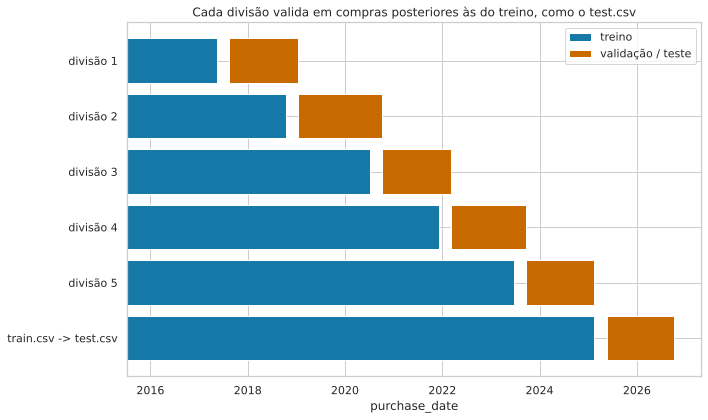

In [8]:
# Passo 3 - as divisões no tempo: treino e validação, com o train.csv inteiro
# e o test.csv na última linha
fig, ax = plt.subplots(figsize=FIGSIZE)
start = train_dates.min()
timeline = [(f"divisão {n}", train_dates.iloc[t].max(), train_dates.iloc[v].min(),
             train_dates.iloc[v].max()) for n, (t, v) in enumerate(splits, start=1)]
timeline.append(("train.csv -> test.csv", train_dates.max(), test_dates.min(),
                 test_dates.max()))

for position, (label, train_end, val_start, val_end) in enumerate(timeline):
    ax.barh(position, train_end - start, left=start, color=PLOT_BLUE,
            label="treino" if position == 0 else None)
    ax.barh(position, val_end - val_start, left=val_start, color=PLOT_ORANGE,
            label="validação / teste" if position == 0 else None)
plt.yticks(np.arange(len(timeline)), [label for label, *_ in timeline])
ax.invert_yaxis()
ax.set(xlabel="purchase_date",
       title="Cada divisão valida em compras posteriores às do treino, como o test.csv")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# Passo 4 - linha de base: mediana / moda nos nulos, one-hot nas categóricas,
# StandardScaler, sem features novas; regressão logística em cada divisão
baseline = evaluate(prepare_base, raw, splits)

print(f"linha de base: F1 {baseline['f1'].mean():.4f} +- {sem(baseline['f1']):.4f}"
      f" | accuracy {baseline['accuracy'].mean():.4f}"
      f" +- {sem(baseline['accuracy']):.4f}")
baseline.round(4)

linha de base: F1 0.7211 +- 0.0097 | accuracy 0.7046 +- 0.0060


,f1,accuracy,linhas treino,colunas
divisão,,,,
1,0.6869,0.6846,1005,82
2,0.7318,0.7124,1987,95
3,0.7365,0.7199,3174,108
4,0.7124,0.7004,4254,123
5,0.7378,0.7059,5272,131


In [10]:
# Passo 5 - pisos: o que se consegue sem modelo nenhum, nas mesmas linhas de validação
# (a classe 1 é a maioritária, por isso "prever sempre 1" é o piso das duas métricas)
floors = pd.DataFrame({
    "taxa do alvo": [y.iloc[v].mean() for _, v in splits],
    "F1 base": baseline["f1"].to_numpy(),
    "F1 sempre 1": [f1_score(y.iloc[v], np.ones(len(v), dtype=int)) for _, v in splits],
    "accuracy base": baseline["accuracy"].to_numpy(),
    "accuracy sempre 1": [y.iloc[v].mean() for _, v in splits],
}, index=baseline.index)

print(f"F1:       base {floors['F1 base'].mean():.4f} contra"
      f" {floors['F1 sempre 1'].mean():.4f} a prever sempre 1 (melhor em"
      f" {(floors['F1 base'] > floors['F1 sempre 1']).sum()} de {len(floors)} divisões)")
print(f"accuracy: base {floors['accuracy base'].mean():.4f} contra"
      f" {floors['accuracy sempre 1'].mean():.4f} a prever sempre 1")
floors.round(4)

F1:       base 0.7211 contra 0.7206 a prever sempre 1 (melhor em 3 de 5 divisões)
accuracy: base 0.7046 contra 0.5638 a prever sempre 1


,taxa do alvo,F1 base,F1 sempre 1,accuracy base,accuracy sempre 1
divisão,,,,,
1,0.5844,0.6869,0.7377,0.6846,0.5844
2,0.5343,0.7318,0.6965,0.7124,0.5343
3,0.5761,0.7365,0.7310,0.7199,0.5761
4,0.5204,0.7124,0.6846,0.7004,0.5204
5,0.6039,0.7378,0.7530,0.7059,0.6039


In [11]:
# Passo 6 - a alternativa por cliente (GroupKFold, W5): que pergunta faz cada desenho?
# Decide-se pela estrutura dos dados e do teste, não pelo resultado (W5, secção 3.4)
group_splits = list(GroupKFold(n_splits=5).split(X, y, groups))
group_run = evaluate(prepare_base, raw, group_splits)


def share_seen(design):
    """% de linhas de validação cujo cliente também está no treino da divisão."""
    return 100 * np.mean([raw[GROUP].iloc[v].isin(raw[GROUP].iloc[t]).mean()
                          for t, v in design])


pd.DataFrame({
    "por tempo (escolhida)": {"% com cliente já visto": share_seen(splits),
                              "valida no futuro": "sim",
                              "F1": baseline["f1"].mean(), "SEM": sem(baseline["f1"])},
    "por cliente": {"% com cliente já visto": share_seen(group_splits),
                    "valida no futuro": "não",
                    "F1": group_run["f1"].mean(), "SEM": sem(group_run["f1"])},
    "test.csv": {"% com cliente já visto": 100 * test_rows_seen.mean(),
                 "valida no futuro": "sim", "F1": np.nan, "SEM": np.nan},
}).T

,% com cliente já visto,valida no futuro,F1,SEM
por tempo (escolhida),84.415584,sim,0.721082,0.009681
por cliente,0.0,não,0.715195,0.019391
test.csv,94.523327,sim,NaN,NaN


In [12]:
# Passo 7 - porquê 90 dias de intervalo: as mesmas janelas de validação, com e sem
# intervalo. Sem ele, entram no treino compras cujo alvo depende das compras da validação
no_gap_splits = time_splits(raw, gap_days=0)
no_gap_run = evaluate(prepare_base, raw, no_gap_splits)


def leaking_rows(design):
    """Linhas de treino feitas menos de 90 dias antes da validação, cujo cliente
    volta a comprar dentro da janela de validação: o alvo delas "vê" a validação."""
    counts = []
    for t, v in design:
        val_start = pd.to_datetime(raw[DATE].iloc[v].min())
        train = raw.iloc[t]
        recent = pd.to_datetime(train[DATE]) >= val_start - pd.Timedelta(days=GAP_DAYS)
        counts.append(int((recent & train[GROUP].isin(raw[GROUP].iloc[v])).sum()))
    return counts


# a diferença no F1 lida como as outras: emparelhada, nas mesmas linhas de validação
gap_effect = paired_delta(no_gap_run["f1"], baseline["f1"])
print(f"sem intervalo - com 90 dias: dF1 {gap_effect['delta']:+.4f}"
      f" +- {gap_effect['SEM']:.4f} -> {gap_effect['veredicto']}")
pd.DataFrame({
    "com 90 dias (escolhida)": {"linhas treino (média)": np.mean([len(t) for t, _ in splits]),
                                "linhas cujo alvo vê a validação": sum(leaking_rows(splits)),
                                "F1": baseline["f1"].mean(),
                                "accuracy": baseline["accuracy"].mean()},
    "sem intervalo": {"linhas treino (média)": np.mean([len(t) for t, _ in no_gap_splits]),
                      "linhas cujo alvo vê a validação": sum(leaking_rows(no_gap_splits)),
                      "F1": no_gap_run["f1"].mean(),
                      "accuracy": no_gap_run["accuracy"].mean()},
}).T

sem intervalo - com 90 dias: dF1 +0.0101 +- 0.0128 -> ruído


,linhas treino (média),linhas cujo alvo vê a validação,F1,accuracy
com 90 dias (escolhida),3138.4,0.0,0.721082,0.704638
sem intervalo,3295.4,725.0,0.731149,0.702968


In [13]:
# Passo 8 - verificar a comparação: a mesma função duas vezes tem de dar exatamente
# o mesmo resultado, e uma coluna de puro ruído tem de sair como "ruído"
def add_placebo(train, test):
    """Linha de base mais uma coluna aleatória, sem nenhuma relação com o alvo."""
    draws = np.random.default_rng(RANDOM_STATE)
    train = train.assign(placebo=draws.normal(size=len(train)))
    test = test.assign(placebo=draws.normal(size=len(test)))
    return prepare_base(train, test)


compare({
    "linha de base outra vez": evaluate(prepare_base, raw, splits),
    "linha de base + coluna aleatória": evaluate(add_placebo, raw, splits),
}, baseline).round(4)

,f1,accuracy,delta,SEM,vitórias,veredicto
linha de base outra vez,0.721082,0.704638,0.0,0.0,0/5,idêntico em todas as divisões
linha de base + coluna aleatória,0.722104,0.705751,0.001021,0.001407,3/5,ruído


In [14]:
# ===== [2.0] BASE COMUM - fim (última célula do 2.0) =====
# Passo 9 - o que fica decidido e como se compara qualquer alternativa daqui em diante:
#
#   arms = {"alternativa A": evaluate(prepare_a, raw, splits), ...}
#   compare(arms, baseline)        # delta, SEM, vitórias e veredicto por alternativa
#
# prepare_a(train, test) ajusta tudo só em `train`, devolve (train, test) sem nulos
# e pode retirar linhas do treino, nunca da validação.
pd.Series({
    "dados de partida": "train.csv; X, y e groups = customer_id",
    "divisões": f"{len(splits)} por tempo (TimeSeriesSplit), {GAP_DAYS} dias de"
                " intervalo entre treino e validação",
    "métrica que decide": f"{METRIC.upper()} (accuracy ao lado)",
    "modelo de medida": f"LogisticRegression(max_iter=1000, random_state={RANDOM_STATE})",
    "linha de base": "mediana / moda, one-hot, StandardScaler, sem features novas",
    "resultado da linha de base": f"F1 {baseline['f1'].mean():.4f}"
                                  f" +- {sem(baseline['f1']):.4f}, accuracy"
                                  f" {baseline['accuracy'].mean():.4f}"
                                  f" +- {sem(baseline['accuracy']):.4f}",
    "regra de comparação": "diferença média emparelhada; abaixo de 2 x SEM é ruído",
}).to_frame("base comum")

,base comum
dados de partida,"train.csv; X, y e groups = customer_id"
divisões,"5 por tempo (TimeSeriesSplit), 90 dias de intervalo entre treino e validação"
métrica que decide,F1 (accuracy ao lado)
modelo de medida,"LogisticRegression(max_iter=1000, random_state=42)"
linha de base,"mediana / moda, one-hot, StandardScaler, sem features novas"
resultado da linha de base,"F1 0.7211 +- 0.0097, accuracy 0.7046 +- 0.0060"
regra de comparação,diferença média emparelhada; abaixo de 2 x SEM é ruído
